# Week 5: Make a slider for your model

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. It needs a GPU runtime (Runtime, then Change runtime type, then A100). You will also need a Hugging Face account that has accepted the license at huggingface.co/black-forest-labs/FLUX.1-dev, and an access token from that account (on Hugging Face, Settings, then Access Tokens). Add the token in Colab's Secrets panel (the key icon on the left) with the name HF_TOKEN, and turn on Notebook access. The outputs below were made on a laptop with the museum chairs model from the week 5 slides.

## 1. Setup

It installs the versions of the libraries we tested with, then checks that the runtime has a GPU and that your Hugging Face token can open FLUX.1 [dev]. If one of them is missing, it stops and prints what to fix.

In [1]:
import os, sys, io, glob, hashlib, tarfile, time
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install diffusers==0.43.0 transformers==5.23.0 accelerate==1.15.0 peft==0.21.3 sentencepiece
import gc, numpy as np, requests, torch
from diffusers import FluxPipeline
from diffusers.pipelines.flux.pipeline_flux import calculate_shift, retrieve_timesteps
from huggingface_hub import auth_check
from PIL import Image, ImageDraw, ImageFont
if IN_COLAB:
    assert torch.cuda.is_available(), "This notebook needs a GPU: Runtime, then Change runtime type, then A100."
    from google.colab import userdata
    try:
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception:
        raise RuntimeError("Add your Hugging Face token in Colab's Secrets panel (the key icon on the left) "
                           "with the name HF_TOKEN, and turn on Notebook access.") from None
try:
    auth_check("black-forest-labs/FLUX.1-dev")
except Exception:
    raise RuntimeError("Hugging Face did not let this token open FLUX.1 [dev]. Check the token, and accept the license "
                       "at huggingface.co/black-forest-labs/FLUX.1-dev with the same account.") from None
dev = "cuda" if torch.cuda.is_available() else "mps"
print("ready")

ready


## 2. Your model

LORA_URL starts as the museum chairs model from the week 5 slides, which was trained with replicate/fast-flux-trainer. Replace it with the link of the model you picked in the train notebook (it is in lora-links.txt), and change TRIGGER and PROMPT to describe your own images. Each link is downloaded into its own folder, and the cell prints which file it loaded.

In [2]:
LORA_URL = "https://replicate.delivery/xezq/KdQIrXFTvNZ0BdOrYZ1i1ovkskK4qiFV8ORnLlIpfX3RMuwLA/flux-lora.tar"  # the week 5 example; paste your own link from lora-links.txt
TRIGGER = "MUSCHR"
PROMPT = f"a photo of a {TRIGGER} chair, museum object photograph on a plain grey backdrop"

def get_lora(url):
    """Download a LoRA (a .safetensors file, or the .tar that Replicate's trainer returns) into its own folder."""
    folder = "lora/" + hashlib.sha1(url.encode()).hexdigest()[:8]
    found = glob.glob(folder + "/**/*.safetensors", recursive=True)
    if not found:
        os.makedirs(folder, exist_ok=True)
        data = requests.get(url, timeout=600).content
        if url.split("?")[0].endswith(".safetensors"):
            open(folder + "/lora.safetensors", "wb").write(data)
        else:
            tarfile.open(fileobj=io.BytesIO(data)).extractall(folder, filter="data")
        found = glob.glob(folder + "/**/*.safetensors", recursive=True)
    assert len(found) == 1, f"Expected one .safetensors file in {url}, found {len(found)}."
    return found[0]

lora_file = get_lora(LORA_URL)
print("LoRA:", lora_file, f"({os.path.getsize(lora_file) // 2**20} MB)")

LoRA: lora/8041a651/flux-lora/flux-lora.safetensors (164 MB)


## 3. Two words

Write the two ends of your slider, each as a short phrase about your subject, for example "ornate chair with carved decoration" and "simple chair with no decoration". This cell also reads PROMPT and your two phrases with the text encoders, then frees the encoders so the image model fits on the GPU.

In [3]:
PLUS = "ornate chair with carved decoration and tufted upholstery"
MINUS = "simple chair with straight lines and no decoration"

# Read PROMPT and the two phrases with the text encoders, then free the encoders so the image model fits on the GPU.
text = FluxPipeline.from_pretrained("black-forest-labs/FLUX.1-dev", transformer=None, vae=None,
                                    torch_dtype=torch.bfloat16).to(dev)
with torch.no_grad():
    E = {k: text.encode_prompt(prompt=t, prompt_2=t, device=dev, max_sequence_length=256)
         for k, t in {"base": PROMPT, "plus": f"{PROMPT}, {PLUS}", "minus": f"{PROMPT}, {MINUS}"}.items()}
del text; gc.collect()
torch.cuda.empty_cache() if dev == "cuda" else torch.mps.empty_cache()
print("words ready")

words ready


## 4. Load the image model

This downloads FLUX.1 [dev] and adds your LoRA, which can take several minutes the first time. If you change LORA_URL later, run sections 2 and 4 again. The second time, this cell only swaps the LoRA instead of loading the whole model again.

In [4]:
if "pipe" in globals():  # the image model is loaded already, so only the LoRA changes
    pipe.unload_lora_weights()
else:
    pipe = FluxPipeline.from_pretrained("black-forest-labs/FLUX.1-dev", text_encoder=None, text_encoder_2=None,
                                        tokenizer=None, tokenizer_2=None, torch_dtype=torch.bfloat16).to(dev)
pipe.load_lora_weights(lora_file)
print("image model ready with", lora_file)

H, W, STEPS, START, SEED = 896, 704, 28, 7, 7

def slider(s, seed=SEED, prompt="base"):
    """One image with the slider at strength s. From step START on, each step adds s times the difference between
    the model's predictions for PLUS and MINUS (the target of Gandikota et al., ECCV 2024, Eq. 7). With s = 0 it is
    an ordinary image of one of the three prompts: "base", "plus" or "minus"."""
    g = torch.Generator("cpu").manual_seed(seed)
    lat, img_ids = pipe.prepare_latents(1, pipe.transformer.config.in_channels // 4, H, W, torch.bfloat16, dev, g, None)
    c = pipe.scheduler.config
    mu = calculate_shift(lat.shape[1], c.get("base_image_seq_len", 256), c.get("max_image_seq_len", 4096),
                         c.get("base_shift", 0.5), c.get("max_shift", 1.15))
    ts, _ = retrieve_timesteps(pipe.scheduler, STEPS, dev, sigmas=np.linspace(1.0, 1 / STEPS, STEPS), mu=mu)
    guidance = torch.full([1], 3.5, device=dev, dtype=torch.float32)
    def predict(key, t):
        pe, pooled, ids = E[key]
        return pipe.transformer(hidden_states=lat, timestep=t.expand(1).to(lat.dtype) / 1000, guidance=guidance,
                                pooled_projections=pooled, encoder_hidden_states=pe, txt_ids=ids, img_ids=img_ids,
                                return_dict=False)[0]
    with torch.no_grad():
        for i, t in enumerate(ts):
            v = predict(prompt, t)
            if i >= START and s != 0:
                v = v + s * (predict("plus", t) - predict("minus", t))
            lat = pipe.scheduler.step(v, t, lat, return_dict=False)[0]
        lat = pipe._unpack_latents(lat, H, W, pipe.vae_scale_factor)
        lat = lat / pipe.vae.config.scaling_factor + pipe.vae.config.shift_factor
        return pipe.image_processor.postprocess(pipe.vae.decode(lat, return_dict=False)[0], output_type="pil")[0]

def labelled_row(cells, title, w=W // 2):
    """Images side by side with a title above and a label under each. A cell can be None to leave a gap."""
    font, small = ImageFont.load_default(22), ImageFont.load_default(16)
    h = round(w * H / W)
    out = Image.new("RGB", (len(cells) * (w + 10) - 10, h + 100), "white")
    d = ImageDraw.Draw(out)
    d.text((0, 4), title, fill="black", font=font)
    for i, cell in enumerate(cells):
        if cell is None:
            continue
        im, label = cell
        out.paste(im.resize((w, h)), (i * (w + 10), 38))
        for n, line in enumerate(label.split("\n")):
            d.text((i * (w + 10), h + 44 + 20 * n), line, fill="black", font=small)
    return out

image model ready with lora/8041a651/flux-lora/flux-lora.safetensors


## 5. Make the strip

It makes five images with the slider at -1.5, -0.75, 0, 0.75 and 1.5, and saves them with their values as strip.jpg. After the first seven steps, each image runs the model three times per step, so it takes about two and a half times as long as a normal image. The cell prints how long each one took.

s = -1.50: 99 seconds


s = -0.75: 98 seconds


s = +0.00: 37 seconds


s = +0.75: 107 seconds


s = +1.50: 93 seconds


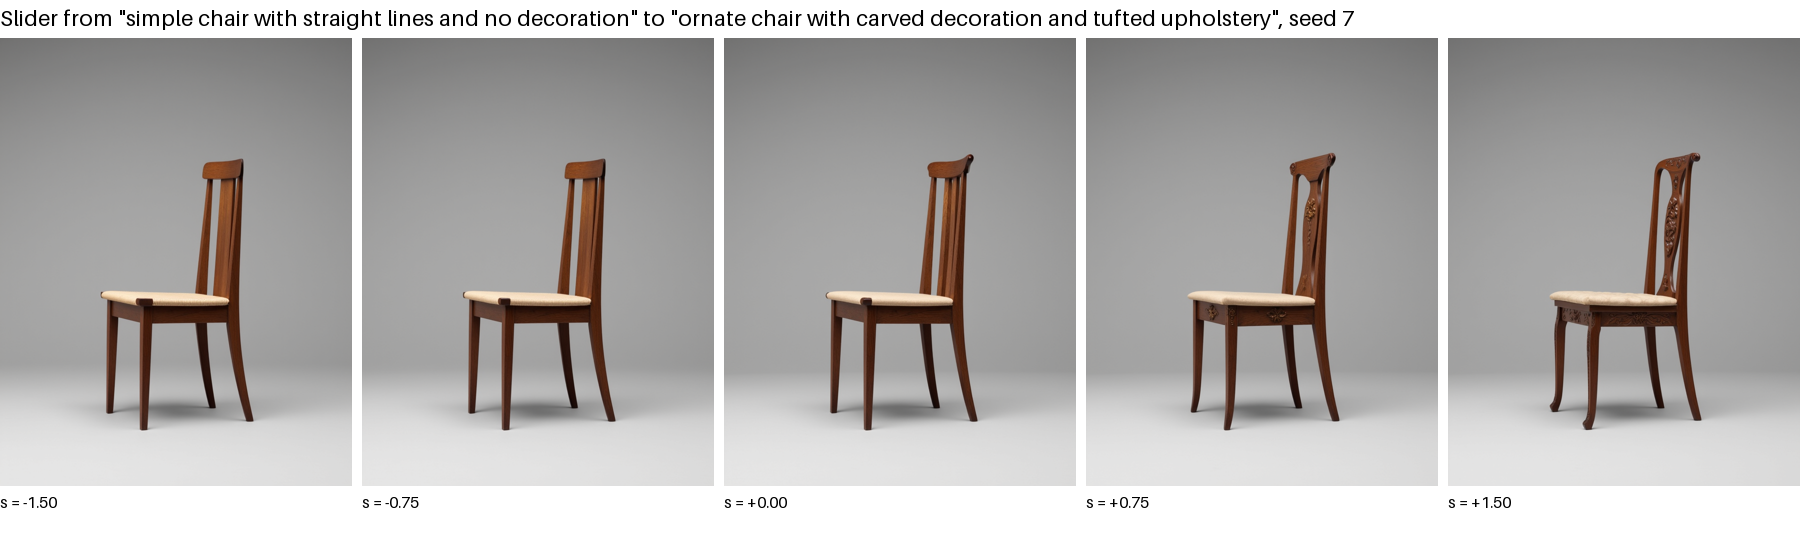

In [5]:
STRENGTHS = [-1.5, -0.75, 0, 0.75, 1.5]
strip = {}
for s in STRENGTHS:
    t0 = time.time()
    strip[s] = slider(s)
    print(f"s = {s:+.2f}: {time.time() - t0:.0f} seconds")
top = labelled_row([(strip[s], f"s = {s:+.2f}") for s in STRENGTHS], f"Slider from \"{MINUS}\" to \"{PLUS}\", seed {SEED}")
top.save("strip.jpg", quality=90)
top

## 6. The same words in the prompt

It makes two more images with the same seed and no slider, one with your MINUS phrase added to PROMPT and one with your PLUS phrase, and puts them under the strip in slider-vs-words.jpg. For the museum chairs, the simple phrase gave a plainer chair with a wooden seat, and the ornate phrase gave a different chair, an armchair with tufted upholstery. Along the strip, the slider kept the same chair. If the five images in your strip look the same, try other phrases or larger slider values. If your design breaks apart, try smaller ones. For the hand-in, download strip.jpg from the Files panel on the left, and you can add slider-vs-words.jpg next to it.

prompt + minus phrase: 38 seconds


prompt + plus phrase: 38 seconds


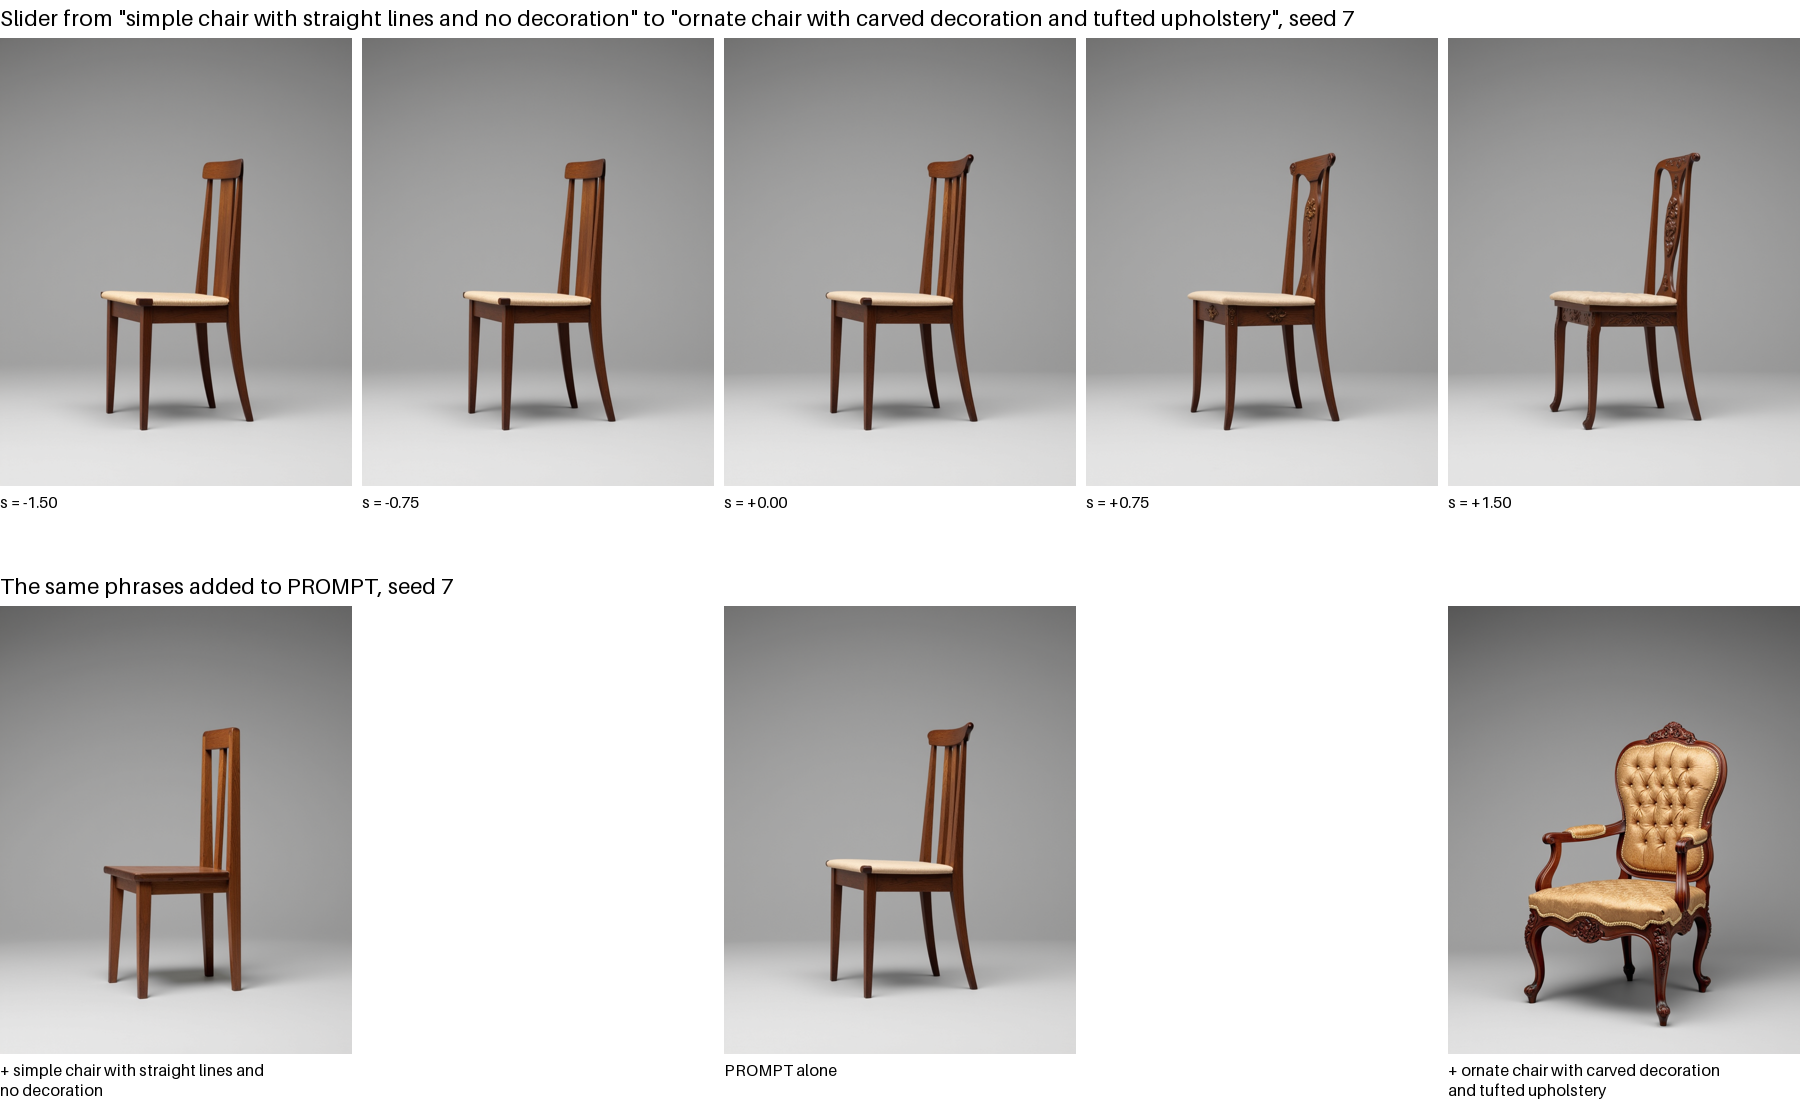

In [6]:
import textwrap
words = {}
for key in ("minus", "plus"):
    t0 = time.time()
    words[key] = slider(0, prompt=key)
    print(f"prompt + {key} phrase: {time.time() - t0:.0f} seconds")
wrap = lambda phrase: "\n".join(textwrap.wrap("+ " + phrase, 38))
bottom = labelled_row([(words["minus"], wrap(MINUS)), None, (strip[0], "PROMPT alone"), None, (words["plus"], wrap(PLUS))],
                      f"The same phrases added to PROMPT, seed {SEED}")
both = Image.new("RGB", (top.width, top.height + bottom.height + 20), "white")
both.paste(top, (0, 0)); both.paste(bottom, (0, top.height + 20))
both.save("slider-vs-words.jpg", quality=90)
both